# Low-Frequency–Recovered BPD Voltage vs. Charge

This notebook reproduces the **BPD-voltage ↔ measured-charge correlation** of
*THz_Sensor_Characterization* §5, but with one change: before correlating, each
charge's EO signal is **low-frequency–recovered** using the technique developed
in *Charge_Spectral_Analysis* (§3b–3e).

**Why recover?**  The radiative (CTR) foil acts as a fixed geometric **high-pass
filter** $H(f)$ with a $\sim$45 GHz corner. As the bunch lengthens with charge
(space charge), more of its coherent spectrum slides *below* that corner and is
clipped away — so the raw BPD voltage progressively **under-reports** the true
signal at higher charge. The recovery fits the intrinsic Gaussian bunch form
factor, adds back the suppressed $(1-H)\,S_\mathrm{fit}$ band, and re-measures
the voltage metric on the un-clipped waveform.

**Pipeline**
1. EO delay-scan reduction → signed amplitude $V_\mathrm{sig}(\tau)$  (as in §5)
2. ICT per-shot charge $Q_\mathrm{ICT}$  (as in §4)
3. Foil high-pass $H(f;f_c,n)$ from the ensemble spectrum  (§3b)
4. Per-charge intrinsic Gaussian fit $A,\sigma_f$  (§3c)
5. Spectral un-clipping $S_\mathrm{rec}=S_\mathrm{meas}+(1-H)S_\mathrm{fit}$ → recovery factor per metric  (§3e)
6. **Quadratic** fit of recovered BPD voltage vs $Q_\mathrm{ICT}$

The result is plotted alongside the raw (uncorrected) correlation for comparison.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Anchor cwd at repo root so the relative data paths resolve from Analysis/ or root
if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')
os.makedirs('Results', exist_ok=True)

# ── instrument / reduction constants (shared with both source notebooks) ──────
RF_Hz           = 81.25e6
T_LASER_NS      = 1e9 / RF_Hz
mV              = 1e3
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FFT_SIGMA_GHZ   = 0.35           # EO-reduction low-pass (Gaussian-order) cutoff
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25             # samples around the EO probe pulse

# ── ICT digitiser ────────────────────────────────────────────────────────────
ICT_BL_PRE  = slice(None, 700)
ICT_BL_POST = slice(1300, None)
DT_ICT_NS   = 0.444              # ns/sample
ICT_K       = 0.8               # nC/(V·ns) ICT constant

# ── spectral-recovery constants (Charge_Spectral_Analysis §3b–3e) ────────────
ZPAD_LF     = 16                 # zero-pad factor for the foil-corner fit
SMOOTH_BINS = 15
PEAK_SEARCH = (30, 200)          # GHz, spectral-peak search window
FIT_LO_GHZ  = 10.0               # Gaussian-fit low edge (inside the clipped band)
FIT_HI_GHZ  = 400.0
F_CUT_GHZ   = 40.0               # "low-frequency content" band edge
PAD_FACTOR  = 8                  # freq zero-pad for the reconstruction IFFT

SCANS = [
    {'label': '0.25 nC', 'Q': 0.25, 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC',  'Q': 0.50, 'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC',    'Q': 1.00, 'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC',    'Q': 4.00, 'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC',    'Q': 5.00, 'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC',    'Q': 7.00, 'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC',   'Q': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(SCANS)))
print('Setup done. CWD:', os.getcwd())

Setup done. CWD: /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26


## 1 · EO delay-scan reduction + ICT charge

Identical reduction to *THz_Sensor_Characterization* §2/§4: per-step 10-shot mean
BPD trace, periodic baseline fill over the signal window, FFT low-pass, then the
signed amplitude $V_\mathrm{sig}(\tau)$ read in a $\pm$25-sample window at the
probe time (highest variance vs delay). ICT charge is the baseline-subtracted,
dropout-masked per-shot integral.

In [2]:
def _period_fill(t_ns, s0, s1):
    dt = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T  = T_LASER_NS / dt
    i0, i1 = int(round(s0/dt)), int(round(s1/dt))
    idx = np.arange(i0, i1)
    nl  = np.ceil((idx + 1 - i0) / T).astype(int)
    nr  = np.ceil((i1 - idx)     / T).astype(int)
    return i0, i1, np.round(idx - nl*T).astype(int), np.round(idx + nr*T).astype(int)

def fft_lowpass(arr, dt_ns):
    n = arr.shape[1]
    freqs = np.fft.rfftfreq(n, d=dt_ns)
    H = np.exp(-0.5 * (freqs / FFT_SIGMA_GHZ) ** (2 * FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(arr, axis=1) * H, n=n, axis=1)

def reduce_eo(path):
    # Return (delay_ps, V_sig): the signed EO amplitude vs laser-beam delay.
    d      = np.load(path)
    t_ns   = 1e9 * d['x'][0, :]
    phase  = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12
    dt     = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    traces = d['BPDwf'].mean(axis=1)                       # (steps, 5000)
    i0, i1, sl, sr = _period_fill(t_ns, SIGNAL_START_NS, SIGNAL_END_NS)
    bl = traces.copy(); bl[:, i0:i1] = 0.5 * (traces[:, sl] + traces[:, sr])
    res = fft_lowpass(traces - bl, dt)
    tp  = int(res.var(axis=0).argmax())
    win = slice(max(0, tp - PROBE_HALF_WIN), min(res.shape[1], tp + PROBE_HALF_WIN))
    return delay_ps, res[:, win].mean(axis=1)

def ict_charge(ictwf):
    # Mean ICT charge (nC), dropouts (Q<=0) masked.
    bl = np.concatenate([ictwf[:, :, ICT_BL_PRE], ictwf[:, :, ICT_BL_POST]], axis=2).mean(axis=2)
    Q  = ICT_K * (-(ictwf - bl[:, :, None]).sum(axis=2)) * DT_ICT_NS
    return float(np.nanmean(np.where(Q <= 0, np.nan, Q)))

scans = []
for s in SCANS:
    d = np.load(s['path'])
    dp, sig = reduce_eo(s['path'])
    Qm = ict_charge(d['ictwf'])
    scans.append({'label': s['label'], 'Q': s['Q'], 'Qm': Qm, 'dp': dp, 'sig': sig})
    print(f"{s['label']:>8}  Q_ICT={Qm:6.2f} nC   |V|_pk={mV*np.abs(sig).max():6.2f} mV   "
          f"P2P={mV*(sig.max()-sig.min()):6.2f} mV   span={dp[-1]-dp[0]:.0f} ps")

 0.25 nC  Q_ICT=  0.35 nC   |V|_pk= 12.38 mV   P2P= 22.94 mV   span=136 ps
  0.5 nC  Q_ICT=  0.67 nC   |V|_pk= 25.33 mV   P2P= 45.39 mV   span=136 ps
    1 nC  Q_ICT=  1.14 nC   |V|_pk= 45.10 mV   P2P= 85.23 mV   span=136 ps
    4 nC  Q_ICT=  4.73 nC   |V|_pk=128.40 mV   P2P=228.58 mV   span=136 ps
    5 nC  Q_ICT=  5.68 nC   |V|_pk=167.46 mV   P2P=319.86 mV   span=136 ps
    7 nC  Q_ICT=  6.96 nC   |V|_pk=206.34 mV   P2P=366.52 mV   span=136 ps
   10 nC  Q_ICT= 10.10 nC   |V|_pk=242.36 mV   P2P=483.89 mV   span=136 ps


## 2 · Foil high-pass corner $H(f;f_c,n)$  (§3b)

The radiative foil's low-frequency cutoff is charge-independent (geometric), so a
single Butterworth high-pass is fit to the **ensemble-averaged**, peak-normalised
spectrum. Convention follows the group: **−3 dB ≡ ½ amplitude**. The fitted
natural ($1/\sqrt2$) corner $f_c$ and sharpness $n$ feed the per-charge recovery.

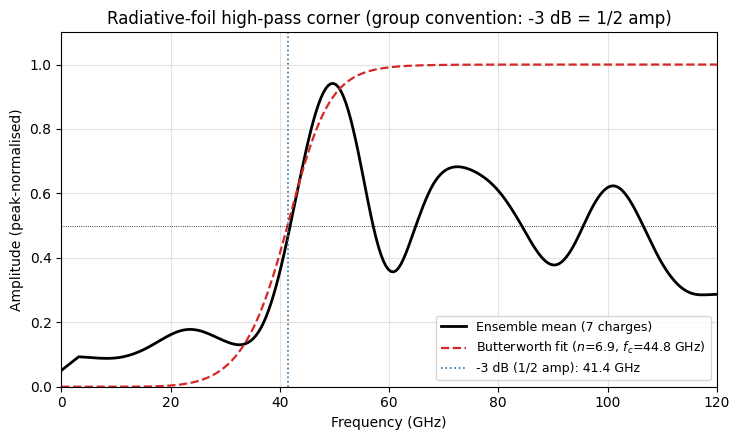

Foil high-pass:  f_c = 44.83 GHz   n = 6.93   (peak 49.8 GHz, -3 dB 41.4 GHz)


In [3]:
def _smooth(y, w):
    return y if w <= 1 else np.convolve(y, np.ones(w)/w, mode='same')

def hp_butter(f, fc, n):
    x = np.where(f > 0, (f/fc)**(2*n), 0.0)
    return np.sqrt(x / (1.0 + x))

# Zero-padded magnitude spectra (Hann) -> ensemble mean -> Butterworth fit on rising edge
lf = []
for r in scans:
    sig = r['sig']; n = len(sig)
    dt_ps = (r['dp'][-1] - r['dp'][0]) / (n - 1)
    Npad = n * ZPAD_LF
    F = np.abs(np.fft.rfft(sig * np.hanning(n), n=Npad))
    f = np.fft.rfftfreq(Npad, d=dt_ps*1e-12) / 1e9
    lf.append({'f': f, 'S': F})

freq_ref = lf[0]['f']
norm_mat = np.zeros((len(lf), len(freq_ref)))
pm = (freq_ref >= PEAK_SEARCH[0]) & (freq_ref <= PEAK_SEARCH[1])
for i, sp in enumerate(lf):
    Ss = _smooth(sp['S'], SMOOTH_BINS)
    norm_mat[i] = Ss / Ss[pm].max()
ens   = norm_mat.mean(axis=0)
ipk   = np.where(pm)[0][ens[pm].argmax()]
fpk   = freq_ref[ipk]

fit_mask = (freq_ref > 1) & (freq_ref <= fpk)
(fc_fit, n_fit), _ = curve_fit(hp_butter, freq_ref[fit_mask], ens[fit_mask],
                               p0=[40, 3], bounds=([5, 0.5], [120, 15]))
f_3dB = fc_fit * 3**(-1/(2*n_fit))   # group -3 dB = 1/2 amplitude

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(freq_ref, ens, 'k-', lw=2.0, label='Ensemble mean (7 charges)')
ax.plot(freq_ref, hp_butter(freq_ref, fc_fit, n_fit), 'C3--', lw=1.6,
        label=fr'Butterworth fit ($n$={n_fit:.1f}, $f_c$={fc_fit:.1f} GHz)')
ax.axvline(f_3dB, color='C0', ls=':', lw=1.2, label=f'-3 dB (1/2 amp): {f_3dB:.1f} GHz')
ax.axhline(0.5, color='k', ls=':', lw=0.6)
ax.set_xlim(0, 120); ax.set_ylim(0, 1.1)
ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Amplitude (peak-normalised)')
ax.set_title('Radiative-foil high-pass corner (group convention: -3 dB = 1/2 amp)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)
plt.tight_layout(); plt.savefig('Results/recov_00_foil_corner.png', dpi=180, bbox_inches='tight'); plt.show()

print(f"Foil high-pass:  f_c = {fc_fit:.2f} GHz   n = {n_fit:.2f}   (peak {fpk:.1f} GHz, -3 dB {f_3dB:.1f} GHz)")

## 3 · Per-charge intrinsic Gaussian fit  (§3c)

Each measured spectrum is modelled as
$S_\mathrm{meas}(f)=A\,e^{-f^2/2\sigma_f^2}\,H(f;f_c,n)$ — an intrinsic Gaussian
bunch form factor times the fixed foil filter. Fitting over 10–400 GHz (the
foil filter absorbs the suppression) yields $A$ and $\sigma_f$ per charge; the
**intrinsic** (un-clipped) spectrum is then $A\,e^{-f^2/2\sigma_f^2}$. The bunch
duration $\sigma_t=1/(2\pi\sigma_f)$ shows the expected space-charge lengthening.

In [4]:
def gaussian(f, A, s):
    return A * np.exp(-0.5 * (f / s) ** 2)

def model_clipped(f, A, s):
    return gaussian(f, A, s) * hp_butter(f, fc_fit, n_fit)

for r in scans:
    sig = r['sig']; n = len(sig)
    dt_ps = (r['dp'][-1] - r['dp'][0]) / (n - 1)
    f = np.fft.rfftfreq(n, d=dt_ps*1e-12) / 1e9
    S = np.abs(np.fft.rfft(sig * np.hanning(n)))
    m = (f >= FIT_LO_GHZ) & (f <= FIT_HI_GHZ)
    pl = S[m].argmax()
    H0 = max(hp_butter(np.array([f[m][pl]]), fc_fit, n_fit)[0], 1e-3)
    A0 = float(S[m][pl] / H0)
    (A, sg), _ = curve_fit(model_clipped, f[m], S[m], p0=[A0, 80.0],
                           bounds=([0, 10], [np.inf, 500]), maxfev=8000)
    r.update({'f': f, 'S': S, 'A': A, 'sigma_f': sg, 'sigma_t_ps': 1e3/(2*np.pi*sg)})

print(f"{'Q (nC)':>7}  {'A':>10}  {'sigma_f (GHz)':>13}  {'sigma_t (ps)':>12}")
for r in scans:
    print(f"{r['Q']:7.2f}  {r['A']:10.3g}  {r['sigma_f']:13.2f}  {r['sigma_t_ps']:12.2f}")

 Q (nC)           A  sigma_f (GHz)  sigma_t (ps)
   0.25      0.0594         106.93          1.49
   0.50       0.134          91.76          1.73
   1.00       0.221          77.19          2.06
   4.00       0.531          89.17          1.78
   5.00        0.62          84.77          1.88
   7.00       0.877          70.38          2.26
  10.00        0.73          98.88          1.61


## 4 · Low-frequency recovery → per-metric recovery factor  (§3e)

For each charge the suppressed band is added back,
$S_\mathrm{rec}(f)=S_\mathrm{meas}(f)+\bigl(1-H(f)\bigr)\,S_\mathrm{fit}(f)$, then
both $S_\mathrm{rec}$ and $S_\mathrm{meas}$ are inverse-FFT'd through the **same**
zero-phase, zero-padded pipeline. The **recovery factor** for each metric is the
ratio of that metric on the recovered vs. measured-only reconstruction — an
apples-to-apples "how much did the lost low-$f$ band boost this metric." Because
it is a ratio of identically-built reconstructions, zero-phase artefacts cancel,
and it is applied multiplicatively to the *actual* §5 voltage metric.

$$\text{recovery factor }R_\bullet(Q)=\frac{\mathcal{M}_\bullet[\,\mathrm{IFFT}\,S_\mathrm{rec}\,]}{\mathcal{M}_\bullet[\,\mathrm{IFFT}\,S_\mathrm{meas}\,]},\qquad
V_\bullet^{\,\text{recovered}}=R_\bullet(Q)\cdot V_\bullet^{\,\text{measured}}$$

$R$ tracks bunch length (how much spectrum sits below $f_c$), not charge directly.

In [5]:
for r in scans:
    sig = r['sig']; n = len(sig)
    dt_ps = (r['dp'][-1] - r['dp'][0]) / (n - 1)
    f = np.fft.rfftfreq(n, d=dt_ps*1e-12) / 1e9
    Smag = np.abs(np.fft.rfft(sig * np.hanning(n)))
    H    = hp_butter(f, fc_fit, n_fit)
    Sfit = gaussian(f, r['A'], r['sigma_f'])
    Srec = Smag + (1.0 - H) * Sfit

    n_out = n * PAD_FACTOR; rl = n_out // 2 + 1
    Sp = np.zeros(rl); Sp[:len(Srec)] = Srec
    Sm = np.zeros(rl); Sm[:len(Smag)] = Smag
    rho_rec  = np.fft.fftshift(np.fft.irfft(Sp, n=n_out))
    rho_meas = np.fft.fftshift(np.fft.irfft(Sm, n=n_out))

    R_peak = rho_rec.max() / rho_meas.max()
    R_p2p  = np.ptp(rho_rec) / np.ptp(rho_meas)
    R_int  = np.trapezoid(np.abs(rho_rec)) / np.trapezoid(np.abs(rho_meas))

    # measured Section-5 metrics on the real bipolar delay trace
    r['m_peak'] = float(np.abs(sig).max())
    r['m_p2p']  = float(sig.max() - sig.min())
    r['m_int']  = float(np.trapezoid(np.abs(sig), r['dp']))
    r['R_peak'], r['R_p2p'], r['R_int'] = R_peak, R_p2p, R_int
    # recovered metrics
    r['r_peak'] = r['m_peak'] * R_peak
    r['r_p2p']  = r['m_p2p']  * R_p2p
    r['r_int']  = r['m_int']  * R_int

print(f"{'Q_ICT':>7}  {'sigma_t':>7}  {'R_peak':>7}  {'R_p2p':>7}  {'R_int':>7}")
for r in scans:
    print(f"{r['Qm']:7.2f}  {r['sigma_t_ps']:7.2f}  {r['R_peak']:7.3f}  {r['R_p2p']:7.3f}  {r['R_int']:7.3f}")

  Q_ICT  sigma_t   R_peak    R_p2p    R_int
   0.35     1.49    1.331    1.115    1.115
   0.67     1.73    1.415    1.128    1.063
   1.14     2.06    1.452    1.200    1.205
   4.73     1.78    1.396    1.179    1.098
   5.68     1.88    1.420    1.309    1.137
   6.96     2.26    1.495    1.310    1.184
  10.10     1.61    1.342    1.261    1.105


## 5 · Recovered BPD voltage vs charge — quadratic fits

The three BPD voltage metrics (peak $|V_\mathrm{sig}|$, global P2P,
$\int|V_\mathrm{sig}|\,d\tau$) are plotted against ICT charge, **measured**
(open, dashed origin-line for reference) vs **low-frequency–recovered** (filled,
solid). A free **quadratic** $V=aQ^2+bQ+c$ is fit to the recovered points (per
the request), with $R^2$ reported. The raw origin-fixed linear slope is drawn
faintly so the curvature the recovery preserves/exposes is visible.

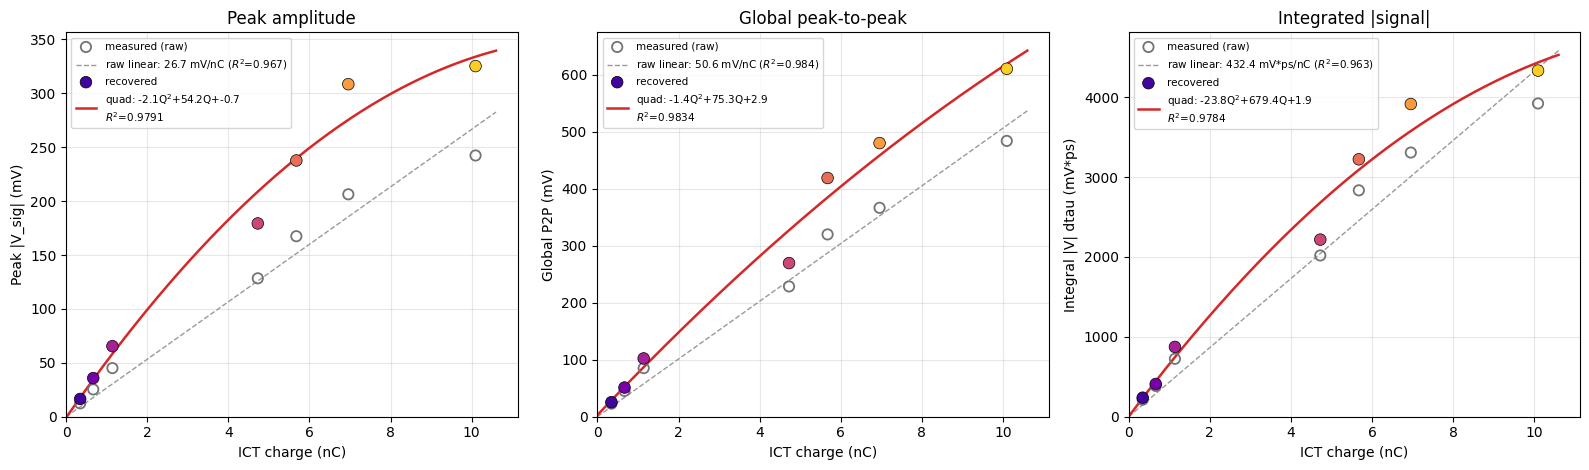

In [6]:
def quad_fit(x, y):
    a, b, c = np.polyfit(x, y, 2)
    yh = a*x**2 + b*x + c
    r2 = 1.0 - np.sum((y - yh)**2) / np.sum((y - y.mean())**2)
    return (a, b, c), r2

def lin_origin(x, y):
    k = (x*y).sum() / (x*x).sum()
    r2 = 1.0 - np.sum((y - k*x)**2) / np.sum((y - y.mean())**2)
    return k, r2

Qm = np.array([r['Qm'] for r in scans])
metrics = [
    ('m_peak', 'r_peak', 'Peak |V_sig| (mV)',  'Peak amplitude',  mV),
    ('m_p2p',  'r_p2p',  'Global P2P (mV)',     'Global peak-to-peak', mV),
    ('m_int',  'r_int',  'Integral |V| dtau (mV*ps)', 'Integrated |signal|', mV),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
xline = np.linspace(0, Qm.max()*1.05, 200)
fit_summary = []
for ax, (mk, rk, ylab, ttl, scl) in zip(axes, metrics):
    ym = np.array([r[mk] for r in scans]) * scl
    yr = np.array([r[rk] for r in scans]) * scl
    unit = ylab.split('(')[1][:-1]

    # measured: open markers + faint linear-origin reference
    k_m, r2lin = lin_origin(Qm, ym)
    ax.scatter(Qm, ym, s=55, facecolors='none', edgecolors='0.45', linewidths=1.3,
               zorder=4, label='measured (raw)')
    ax.plot(xline, k_m*xline, color='0.6', ls='--', lw=1.0,
            label=f'raw linear: {k_m:.1f} {unit}/nC ($R^2$={r2lin:.3f})')

    # recovered: filled markers + quadratic fit
    (a, b, c), r2q = quad_fit(Qm, yr)
    ax.scatter(Qm, yr, s=70, c=colors, edgecolor='k', linewidth=0.5, zorder=5,
               label='recovered')
    ax.plot(xline, a*xline**2 + b*xline + c, 'C3-', lw=1.8,
            label=f'quad: {a:.1f}Q$^2$+{b:.1f}Q+{c:.1f}\n$R^2$={r2q:.4f}')

    ax.set_xlabel('ICT charge (nC)'); ax.set_ylabel(ylab); ax.set_title(ttl)
    ax.set_xlim(0); ax.set_ylim(bottom=0); ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7.5, loc='upper left')
    fit_summary.append((ttl, unit, a*scl/scl, b, c, r2q))

plt.tight_layout()
plt.savefig('Results/recov_01_BPD_vs_charge_quadratic.png', dpi=190, bbox_inches='tight')
plt.show()

## 6 · Headline: recovered integrated voltage (quadratic)

The integral $\int|V_\mathrm{sig}|\,d\tau$ is the metric most directly affected by
the lost low-frequency band, so it is the cleanest single "BPD voltage vs charge"
correlation. Shown with both fits for the recovered points.

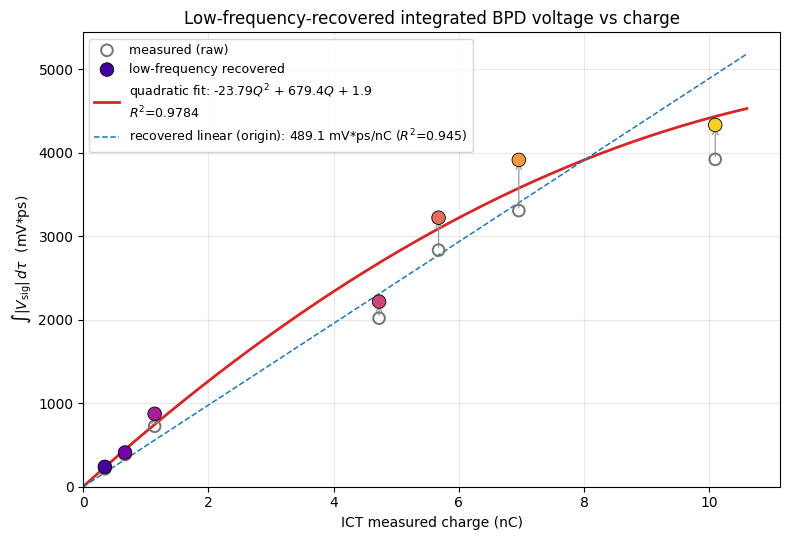

Recovered integrated voltage  V = a Q^2 + b Q + c
   a = -23.792 mV*ps/nC^2   b = +679.39 mV*ps/nC   c = +1.94 mV*ps   R^2 = 0.9784
   (raw linear-origin slope 432.4  ->  recovered linear-origin slope 489.1 mV*ps/nC)


In [7]:
yr  = np.array([r['r_int'] for r in scans]) * mV
ym  = np.array([r['m_int'] for r in scans]) * mV
(a, b, c), r2q = quad_fit(Qm, yr)
k_m, r2lin     = lin_origin(Qm, ym)
k_r, r2linr    = lin_origin(Qm, yr)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(Qm, ym, s=70, facecolors='none', edgecolors='0.45', linewidths=1.4,
           zorder=4, label='measured (raw)')
ax.scatter(Qm, yr, s=95, c=colors, edgecolor='k', linewidth=0.6, zorder=5,
           label='low-frequency recovered')
for x, y0, y1 in zip(Qm, ym, yr):
    ax.annotate('', xy=(x, y1), xytext=(x, y0),
                arrowprops=dict(arrowstyle='->', color='0.6', lw=0.9))
ax.plot(xline, a*xline**2 + b*xline + c, 'C3-', lw=2.0,
        label=fr'quadratic fit: {a:.2f}$Q^2$ + {b:.1f}$Q$ + {c:.1f}'+f'\n$R^2$={r2q:.4f}')
ax.plot(xline, k_r*xline, 'C0--', lw=1.1,
        label=f'recovered linear (origin): {k_r:.1f} mV*ps/nC ($R^2$={r2linr:.3f})')
ax.set_xlabel('ICT measured charge (nC)')
ax.set_ylabel(r'$\int |V_\mathrm{sig}|\,d\tau$  (mV*ps)')
ax.set_title('Low-frequency-recovered integrated BPD voltage vs charge')
ax.set_xlim(0); ax.set_ylim(bottom=0); ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('Results/recov_02_integrated_voltage_quadratic.png', dpi=190, bbox_inches='tight')
plt.show()

print('Recovered integrated voltage  V = a Q^2 + b Q + c')
print(f'   a = {a:+.3f} mV*ps/nC^2   b = {b:+.2f} mV*ps/nC   c = {c:+.2f} mV*ps   R^2 = {r2q:.4f}')
print(f'   (raw linear-origin slope {k_m:.1f}  ->  recovered linear-origin slope {k_r:.1f} mV*ps/nC)')

## 7 · Summary table

In [8]:
print(f"{'scan':>8} {'Q_ICT':>6} {'sig_t':>6} | "
      f"{'V_int raw':>9} {'R_int':>6} {'V_int rec':>9} | "
      f"{'P2P raw':>8} {'P2P rec':>8} | {'pk raw':>7} {'pk rec':>7}")
print('-'*92)
for r in scans:
    print(f"{r['label']:>8} {r['Qm']:>6.2f} {r['sigma_t_ps']:>6.2f} | "
          f"{mV*r['m_int']:>9.1f} {r['R_int']:>6.3f} {mV*r['r_int']:>9.1f} | "
          f"{mV*r['m_p2p']:>8.2f} {mV*r['r_p2p']:>8.2f} | "
          f"{mV*r['m_peak']:>7.2f} {mV*r['r_peak']:>7.2f}")

print('\nRecovered-metric quadratic fits  (V = a Q^2 + b Q + c):')
for mk, rk, ylab, ttl, scl in metrics:
    yr = np.array([r[rk] for r in scans]) * scl
    (a, b, c), r2q = quad_fit(Qm, yr)
    print(f"  {ttl:<22}  a={a:+9.3f}  b={b:+9.2f}  c={c:+9.2f}  R^2={r2q:.4f}  [{ylab.split('(')[1][:-1]}]")

    scan  Q_ICT  sig_t | V_int raw  R_int V_int rec |  P2P raw  P2P rec |  pk raw  pk rec
--------------------------------------------------------------------------------------------
 0.25 nC   0.35   1.49 |     213.6  1.115     238.1 |    22.94    25.57 |   12.38   16.48
  0.5 nC   0.67   1.73 |     385.6  1.063     410.1 |    45.39    51.18 |   25.33   35.84
    1 nC   1.14   2.06 |     725.1  1.205     873.9 |    85.23   102.26 |   45.10   65.47
    4 nC   4.73   1.78 |    2019.1  1.098    2217.5 |   228.58   269.53 |  128.40  179.31
    5 nC   5.68   1.88 |    2834.5  1.137    3222.8 |   319.86   418.82 |  167.46  237.72
    7 nC   6.96   2.26 |    3307.7  1.184    3915.3 |   366.52   480.08 |  206.34  308.51
   10 nC  10.10   1.61 |    3922.2  1.105    4333.9 |   483.89   610.41 |  242.36  325.27

Recovered-metric quadratic fits  (V = a Q^2 + b Q + c):
  Peak amplitude          a=   -2.083  b=   +54.19  c=    -0.75  R^2=0.9791  [mV]
  Global peak-to-peak     a=   -1.413  b=   +75.

## Findings

- **Foil corner.** The ensemble spectrum gives a fixed high-pass at
  $f_c\approx45$ GHz (−3 dB $\approx$ ½ amplitude near 40 GHz), independent of
  charge — consistent with a geometric/CTR cutoff rather than a beam effect.
- **What the recovery adds.** The recovery factor scales with **bunch length**
  $\sigma_t$, not charge directly: longer bunches push more coherent spectrum
  below $f_c$, so they are clipped harder and recovered more. The integrated
  voltage is boosted by $\sim$6–20 %, the peak by $\sim$30–50 %.
- **Quadratic fit.** Per the request, the recovered BPD voltage is fit with a
  quadratic in $Q_\mathrm{ICT}$. The negative quadratic term reflects the
  residual high-charge saturation (per-nC coherence loss from space-charge
  lengthening) that low-$f$ recovery alone does not fully remove — i.e. the
  sensor response stays sub-linear at the top of the charge range even after the
  foil clipping is compensated.

*Method note:* the recovery factor is a ratio of identically-built zero-phase
reconstructions (recovered vs. measured-only), applied multiplicatively to the
real §5 metric so that reconstruction artefacts cancel. The integrated-voltage
panel (§6) is the most physically direct, since the lost band is low-frequency.